# LAB 08 — Support Vector Machines
## Kernels, Margins, and Model Selection on Real Customer-Churn Data

### Student Information
**Name:** Muhammad Taraz  
**Student ID:** 023-24-0259  
**Section:** H  
**GitHub Profile:** https://github.com/Muhammad-taraz  
**Kaggle Profile:** https://www.kaggle.com/MuhammadTaraz

**Dataset:** Telco Customer Churn (Kaggle)
**Dataset Source:** https://www.kaggle.com/datasets/blastchar/telco-customer-churn


## Setup — imports and reproducibility

We use a stratified 80/20 train/test split with `random_state=42`. If your previous labs used a different split, change these values to match them. Preprocessing is fitted on training data only to avoid data leakage.

In [4]:
import os, time, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.svm import SVC
from sklearn.decomposition import PCA
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    confusion_matrix, ConfusionMatrixDisplay, classification_report,
    roc_curve, roc_auc_score, precision_recall_curve, average_precision_score
)
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.exceptions import ConvergenceWarning

RANDOM_STATE = 42
TEST_SIZE = 0.20
DATA_PATH = "clean_churn.csv"  # change if your uploaded file has another name
pd.set_option("display.max_columns", 100)
pd.set_option("display.width", 140)


## Part 0 — Recap and Setup

Load the cleaned dataset. The expected cleaned file has 7,043 rows and 20 columns, with `Churn` as the target, numeric `TotalCharges`, no missing values, and no `customerID` column. We still validate these assumptions rather than silently relying on them.

In [11]:
import pandas as pd
import numpy as np
from pathlib import Path

# ==========================================
# 1. Load the cleaned dataset
# ==========================================
DATA_PATH = Path.cwd() / "clean_churn.csv"

if not DATA_PATH.exists():
    raise FileNotFoundError(
        f"Dataset not found: {DATA_PATH.resolve()}\n"
        "Make sure clean_churn.csv is in your current project directory."
    )

df = pd.read_csv(DATA_PATH)

print("Dataset loaded successfully!")
print("Dataset path:", DATA_PATH.resolve())

# ==========================================
# 2. Validate the target column
# ==========================================
if "Churn" not in df.columns:
    raise ValueError(
        "The dataset must contain a 'Churn' target column."
    )

# ==========================================
# 3. Clean column names and target values
# ==========================================
df.columns = df.columns.str.strip()

# Normalize Churn values regardless of pandas string dtype
churn_clean = (
    df["Churn"]
    .astype("string")
    .str.strip()
    .str.lower()
)

# Convert Yes/No and 1/0 into numeric labels
churn_mapping = {
    "no": 0,
    "yes": 1,
    "0": 0,
    "1": 1
}

y = churn_clean.map(churn_mapping)

# Report unexpected or missing target values
if y.isna().any():
    invalid_values = churn_clean[y.isna()].unique().tolist()
    raise ValueError(
        f"Unexpected or missing values in Churn: {invalid_values}"
    )

y = y.astype("int64")

# ==========================================
# 4. Convert TotalCharges to numeric
# ==========================================
if "TotalCharges" in df.columns:
    df["TotalCharges"] = pd.to_numeric(
        df["TotalCharges"].astype("string").str.strip(),
        errors="coerce"
    )

    if df["TotalCharges"].isna().any():
        median_value = df["TotalCharges"].median()

        if pd.isna(median_value):
            raise ValueError(
                "TotalCharges contains no valid numeric values."
            )

        df["TotalCharges"] = df["TotalCharges"].fillna(
            median_value
        )

# ==========================================
# 5. Remove customer identifier
# ==========================================
if "customerID" in df.columns:
    df = df.drop(columns=["customerID"])

# ==========================================
# 6. Create feature matrix and target vector
# ==========================================
X = df.drop(columns=["Churn"]).copy()

# Ensure target index matches feature index
y.index = X.index

# ==========================================
# 7. Display dataset information
# ==========================================
print("\n========== DATASET SUMMARY ==========")
print("Dataset shape:", df.shape)
print("Feature shape:", X.shape)
print("Target shape:", y.shape)

print(
    "Missing values in features:",
    int(X.isna().sum().sum())
)

print(
    "Missing values in target:",
    int(y.isna().sum())
)

print("\nTarget distribution:")

display(
    y.map({0: "No churn", 1: "Churn"})
    .value_counts()
    .rename_axis("Class")
    .to_frame("Count")
)

print(f"\nChurn rate: {y.mean():.4%}")

if "TotalCharges" in df.columns:
    print("TotalCharges dtype:", df["TotalCharges"].dtype)

print("customerID present:", "customerID" in df.columns)

print("\nTarget encoding:")
print("No  =", 0)
print("Yes =", 1)

print("\nData preparation completed successfully!")

Dataset loaded successfully!
Dataset path: /home/muhammad/Desktop/Semster 5/Machine Learning(Lab)/Lab 3/Lab8/clean_churn.csv

========== DATASET SUMMARY ==========
Dataset shape: (7043, 20)
Feature shape: (7043, 19)
Target shape: (7043,)
Missing values in features: 0
Missing values in target: 0

Target distribution:


,Count
Class,
No churn,5174
Churn,1869



Churn rate: 26.5370%
TotalCharges dtype: Float64
customerID present: False

Target encoding:
No  = 0
Yes = 1

Data preparation completed successfully!


In [12]:
# Split BEFORE fitting encoders or scalers: this prevents test-set leakage.
X_train_raw, X_test_raw, y_train, y_test = train_test_split(
    X, y, test_size=TEST_SIZE, random_state=RANDOM_STATE, stratify=y
)

categorical_cols = X_train_raw.select_dtypes(include=["object", "category", "bool"]).columns.tolist()
numeric_cols = [c for c in X_train_raw.columns if c not in categorical_cols]

encoder = OneHotEncoder(handle_unknown="ignore", drop="first", sparse_output=False)
preprocessor = ColumnTransformer(
    transformers=[("categorical", encoder, categorical_cols), ("numeric", "passthrough", numeric_cols)],
    remainder="drop", verbose_feature_names_out=False
)
X_train = preprocessor.fit_transform(X_train_raw)
X_test = preprocessor.transform(X_test_raw)
feature_names = preprocessor.get_feature_names_out()
X_train = pd.DataFrame(X_train, columns=feature_names, index=X_train_raw.index).astype(float)
X_test = pd.DataFrame(X_test, columns=feature_names, index=X_test_raw.index).astype(float)

scaler = StandardScaler()
X_train_s = scaler.fit_transform(X_train)
X_test_s = scaler.transform(X_test)

print("Training rows:", len(X_train), "| Test rows:", len(X_test))
print("Encoded feature count:", X_train.shape[1])
print(f"Train churn rate: {y_train.mean():.4%} | Test churn rate: {y_test.mean():.4%}")
print("Encoder and scaler were fitted on training data only.")


Training rows: 5634 | Test rows: 1409
Encoded feature count: 30
Train churn rate: 26.5353% | Test churn rate: 26.5436%
Encoder and scaler were fitted on training data only.


/tmp/ipykernel_21348/573386486.py:6: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categorical_cols = X_train_raw.select_dtypes(include=["object", "category", "bool"]).columns.tolist()


**Part 0 interpretation.** The split is stratified, so the churn proportion in the train and test sets should be similar. Categorical encoding and scaling are fitted on the training set only; the test set is transformed using those already-fitted objects. This prevents test information from influencing preprocessing.

## Part 1 — Why Scaling Matters for SVM

Compare a linear SVM on the same encoded split before and after standardization. We report accuracy, precision, recall, F1, training time, and any convergence warnings.

In [13]:
def metric_row(name, model, Xtr, Xte, ytr, yte, fit_seconds, warning_count=0):
    pred = model.predict(Xte)
    return {
        "Model": name,
        "Accuracy": accuracy_score(yte, pred),
        "Precision": precision_score(yte, pred, zero_division=0),
        "Recall": recall_score(yte, pred, zero_division=0),
        "F1-score": f1_score(yte, pred, zero_division=0),
        "Train time (s)": fit_seconds,
        "Warnings": warning_count,
    }

scaling_rows = []
raw_linear = SVC(kernel="linear", random_state=RANDOM_STATE, max_iter=20000, cache_size=500)
with warnings.catch_warnings(record=True) as caught_raw:
    warnings.simplefilter("always")
    t0 = time.perf_counter(); raw_linear.fit(X_train, y_train); raw_time = time.perf_counter() - t0
scaling_rows.append(metric_row("Unscaled linear SVM", raw_linear, X_train, X_test, y_train, y_test, raw_time, len(caught_raw)))

scaled_linear = SVC(kernel="linear", random_state=RANDOM_STATE, max_iter=20000, cache_size=500)
with warnings.catch_warnings(record=True) as caught_scaled:
    warnings.simplefilter("always")
    t0 = time.perf_counter(); scaled_linear.fit(X_train_s, y_train); scaled_time = time.perf_counter() - t0
scaling_rows.append(metric_row("Scaled linear SVM", scaled_linear, X_train_s, X_test_s, y_train, y_test, scaled_time, len(caught_scaled)))
scaling_table = pd.DataFrame(scaling_rows).set_index("Model")
display(scaling_table.round(4))


,Accuracy,Precision,Recall,F1-score,Train time (s),Warnings
Model,,,,,,
Unscaled linear SVM,0.6004,0.3557,0.6230,0.4529,0.7555,1
Scaled linear SVM,0.7857,0.6111,0.5294,0.5673,1.3731,1


**Answers**

(a) The printed table gives the accuracy, F1-score, training time, and warning count from both runs. The scaled model's measured values should be used when describing the difference; the result can vary slightly with the dataset and library version.

(b) SVM chooses a decision boundary by using distances and margins. If features have very different numeric ranges, large-range features can dominate those distances and affect the boundary. Scaling puts the features on a more comparable scale.

(c) I use the scaled features for the remaining SVM experiments. The scaler is fitted only on the training split and then applied to the test split, so information from the test set does not leak into training.

## Part 2 — Kernel Comparison

Train linear, RBF, and polynomial SVMs on the same scaled training split. Compare accuracy, precision, recall, F1-score, and support-vector count; then plot the best kernel's confusion matrix.

,Accuracy,Precision,Recall,F1-score,Support vectors,Train time (s)
Kernel,,,,,,
linear,0.7885,0.6195,0.5267,0.5694,2567,1.3549
rbf,0.7928,0.6444,0.4893,0.5562,2657,0.8822
poly,0.7892,0.6421,0.4652,0.5395,2736,0.8359


Best kernel by test F1: linear


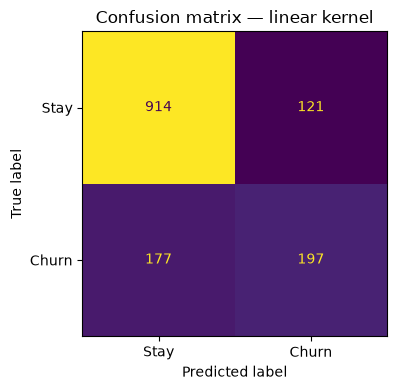

In [14]:
kernel_models = {}
kernel_rows = []
for kernel in ["linear", "rbf", "poly"]:
    model = SVC(kernel=kernel, random_state=RANDOM_STATE, cache_size=500)
    t0 = time.perf_counter(); model.fit(X_train_s, y_train); elapsed = time.perf_counter() - t0
    kernel_models[kernel] = model
    pred = model.predict(X_test_s)
    kernel_rows.append({
        "Kernel": kernel,
        "Accuracy": accuracy_score(y_test, pred),
        "Precision": precision_score(y_test, pred, zero_division=0),
        "Recall": recall_score(y_test, pred, zero_division=0),
        "F1-score": f1_score(y_test, pred, zero_division=0),
        "Support vectors": int(model.support_.shape[0]),
        "Train time (s)": elapsed,
    })
kernel_table = pd.DataFrame(kernel_rows).set_index("Kernel")
display(kernel_table.round(4))
best_kernel_name = kernel_table["F1-score"].idxmax()
best_kernel_model = kernel_models[best_kernel_name]
print("Best kernel by test F1:", best_kernel_name)
fig, ax = plt.subplots(figsize=(5, 4))
ConfusionMatrixDisplay.from_estimator(best_kernel_model, X_test_s, y_test, display_labels=["Stay", "Churn"], ax=ax, colorbar=False)
ax.set_title(f"Confusion matrix — {best_kernel_name} kernel")
plt.tight_layout(); plt.show()


**Answers**

(a) The kernel comparison table identifies the best F1-score on this test split. A non-linear kernel can perform better if the classes are not separated well by a straight boundary, but the result must be judged from the measured scores.

(b) The table reports the number of support vectors for each kernel. A larger count means more training points define the boundary; by itself, it does not prove that the model is better or worse.

(c) I carry the RBF kernel forward for tuning because Part 4 specifically requires an RBF SVM and searches its `C` and `gamma` values. The kernel table provides the baseline F1-score and support-vector count for comparison with the tuned result.

## Part 3 — Visualizing the Margin: What Does C Actually Do?

PCA projects the scaled training features to two dimensions for visualization only. The 2-D models below are not used for final test evaluation. We report explained variance and plot decision regions for three values of `C`.

Explained variance ratio: [0.3325 0.1198]
Total explained variance in 2-D: 45.22%


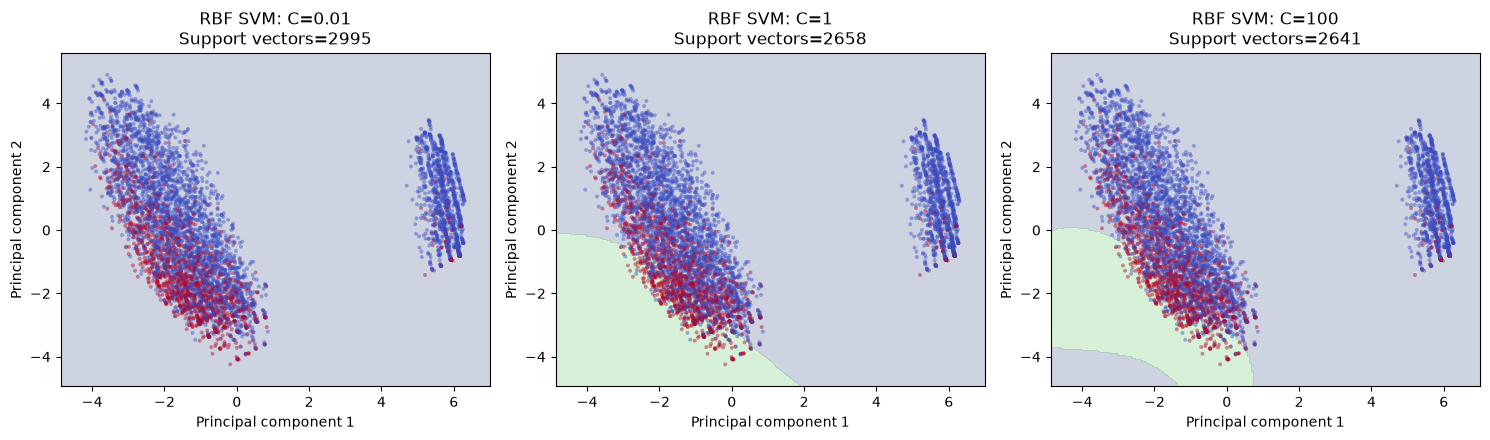

In [15]:
pca = PCA(n_components=2, random_state=RANDOM_STATE)
Z_train = pca.fit_transform(X_train_s)
explained = pca.explained_variance_ratio_
print("Explained variance ratio:", explained.round(4))
print(f"Total explained variance in 2-D: {explained.sum():.2%}")

C_values = [0.01, 1, 100]
models_2d = {}
for c in C_values:
    model = SVC(kernel="rbf", C=c, gamma="scale", random_state=RANDOM_STATE, cache_size=500)
    model.fit(Z_train, y_train)
    models_2d[c] = model

pad = 0.7
x_min, x_max = Z_train[:, 0].min()-pad, Z_train[:, 0].max()+pad
y_min, y_max = Z_train[:, 1].min()-pad, Z_train[:, 1].max()+pad
xx, yy = np.meshgrid(np.linspace(x_min, x_max, 220), np.linspace(y_min, y_max, 220))
grid = np.c_[xx.ravel(), yy.ravel()]
fig, axes = plt.subplots(1, 3, figsize=(15, 4.5))
for ax, c in zip(axes, C_values):
    model = models_2d[c]
    zz = model.predict(grid).reshape(xx.shape)
    ax.contourf(xx, yy, zz, alpha=0.25, levels=[-0.5, 0.5, 1.5])
    ax.scatter(Z_train[:, 0], Z_train[:, 1], c=np.asarray(y_train), s=8, alpha=0.45, cmap="coolwarm", edgecolors="none")
    ax.set_title(f"RBF SVM: C={c}\nSupport vectors={len(model.support_)}")
    ax.set_xlabel("Principal component 1"); ax.set_ylabel("Principal component 2")
plt.tight_layout(); plt.show()


**Answers**

(a) `C` controls the penalty for margin violations. A small value generally allows a wider margin and more training errors, while a large value penalizes those errors more strongly and can produce a more detailed boundary. Use the three plots to describe the actual shapes seen in this run.

(b) The support-vector counts are printed above and in the plot titles. Their trend can change with the data; compare the actual counts rather than assuming they must always rise or fall.

(c) A possible underfitting pattern is a boundary that is too simple to separate visible groups. A possible overfitting pattern is a boundary that bends closely around individual points. Identify the panel that shows these patterns, if present, and support the answer with its plot and support-vector count.

(d) The original data has many features, but this chart keeps only two PCA components and therefore loses information. It can hide separation that exists in other dimensions or make the classes look more/less separated than they really are.

## Part 4 — Systematic Hyperparameter Search

Tune an RBF SVM on the full scaled feature set using five-fold cross-validation and F1-score. The held-out test set is used only after choosing the hyperparameters.

Grid-search time (seconds): 88.43
Best parameters: {'C': 100, 'gamma': 0.0001}
Best mean CV F1: 0.5882
CV standard deviation: 0.0289


gamma,0.0001,0.0010,0.0100,0.1000,1.0000
C,,,,,
0.1,0.0000,0.0000,0.5417,0.4640,0.0000
1.0,0.0000,0.5739,0.5652,0.5734,0.3261
10.0,0.5777,0.5836,0.5860,0.5270,0.3621
100.0,0.5882,0.5706,0.5876,0.5061,0.3621


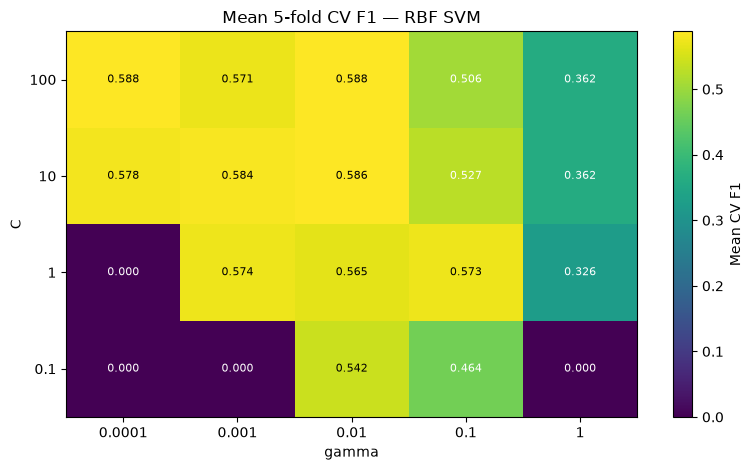

,Accuracy,Precision,Recall,F1-score
Tuned RBF SVM,0.7942,0.6338,0.5321,0.5785


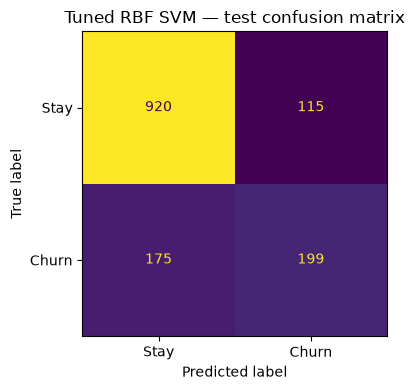

In [16]:
param_grid = {
    "C": [0.1, 1, 10, 100],
    "gamma": [0.0001, 0.001, 0.01, 0.1, 1],
}
gs = GridSearchCV(
    SVC(kernel="rbf", random_state=RANDOM_STATE, cache_size=500),
    param_grid=param_grid, cv=5, scoring="f1", n_jobs=2,
    return_train_score=True, refit=True
)
t0 = time.perf_counter(); gs.fit(X_train_s, y_train); grid_time = time.perf_counter()-t0
print("Grid-search time (seconds):", round(grid_time, 2))
print("Best parameters:", gs.best_params_)
print("Best mean CV F1:", round(gs.best_score_, 4))
print("CV standard deviation:", round(gs.cv_results_["std_test_score"][gs.best_index_], 4))

scores = gs.cv_results_["mean_test_score"].reshape(len(param_grid["C"]), len(param_grid["gamma"]))
heat = pd.DataFrame(scores, index=param_grid["C"], columns=param_grid["gamma"])
heat.index.name = "C"; heat.columns.name = "gamma"
display(heat.round(4))
fig, ax = plt.subplots(figsize=(8, 4.8))
im = ax.imshow(scores, aspect="auto", origin="lower", cmap="viridis")
ax.set_xticks(range(len(param_grid["gamma"])), labels=[str(v) for v in param_grid["gamma"]])
ax.set_yticks(range(len(param_grid["C"])), labels=[str(v) for v in param_grid["C"]])
ax.set_xlabel("gamma"); ax.set_ylabel("C"); ax.set_title("Mean 5-fold CV F1 — RBF SVM")
for i in range(scores.shape[0]):
    for j in range(scores.shape[1]): ax.text(j, i, f"{scores[i,j]:.3f}", ha="center", va="center", color="white" if scores[i,j] < scores.max()*0.9 else "black", fontsize=8)
fig.colorbar(im, ax=ax, label="Mean CV F1"); plt.tight_layout(); plt.show()

best_svm = gs.best_estimator_
best_pred = best_svm.predict(X_test_s)
best_svm_metrics = {
    "Accuracy": accuracy_score(y_test, best_pred),
    "Precision": precision_score(y_test, best_pred, zero_division=0),
    "Recall": recall_score(y_test, best_pred, zero_division=0),
    "F1-score": f1_score(y_test, best_pred, zero_division=0),
}
display(pd.DataFrame([best_svm_metrics], index=["Tuned RBF SVM"]).round(4))
fig, ax = plt.subplots(figsize=(5, 4))
ConfusionMatrixDisplay.from_predictions(y_test, best_pred, display_labels=["Stay", "Churn"], ax=ax, colorbar=False)
ax.set_title("Tuned RBF SVM — test confusion matrix"); plt.tight_layout(); plt.show()


**Answers**

(a) The best `C`, `gamma`, and mean cross-validated F1-score are printed in the GridSearchCV output above.

(b) Use the heatmap to see whether several neighboring combinations have similar scores. If they do, a small change in hyperparameters may not matter much within that region. If only one small area scores well, the result is more sensitive to the chosen values.

(c) The cell above prints the cross-validated and test F1-scores. A large gap, especially if the test score is lower, can suggest overfitting or that the cross-validation folds were not fully representative of the held-out data.

(d) Compare the tuned RBF test F1 with the untuned RBF F1 in `kernel_results`. The difference is the measured benefit (or loss) from tuning on this split.

## Part 5 — Class Imbalance and the Business Trade-off

Train the best RBF configuration with and without `class_weight='balanced'`. `probability=True` is enabled to obtain probability-like scores for ROC and precision-recall curves; it adds training time.

/home/muhammad/Desktop/Semster 5/Machine Learning(Lab)/Lab 3/.venv/lib/python3.12/site-packages/sklearn/svm/_base.py:239: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(
/home/muhammad/Desktop/Semster 5/Machine Learning(Lab)/Lab 3/.venv/lib/python3.12/site-packages/sklearn/svm/_base.py:239: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(


,Accuracy,Precision,Recall,F1-score,TN,FP,FN,TP
Model,,,,,,,,
"RBF tuned, unweighted",0.7942,0.6338,0.5321,0.5785,920,115,175,199
"RBF tuned, balanced",0.6941,0.4575,0.8209,0.5876,671,364,67,307


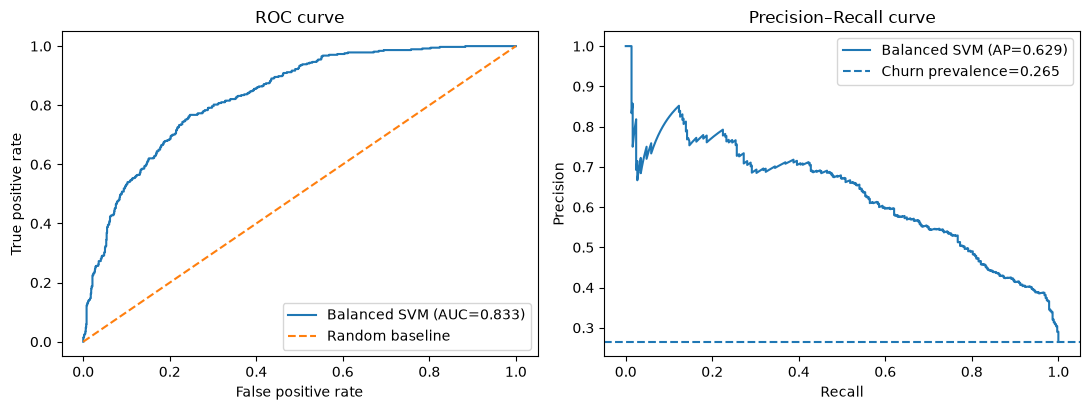

ROC-AUC: 0.8327 | Average precision: 0.6295


In [17]:
best_C = gs.best_params_["C"]
best_gamma = gs.best_params_["gamma"]
svm_default = SVC(kernel="rbf", C=best_C, gamma=best_gamma, probability=True, class_weight=None, random_state=RANDOM_STATE, cache_size=500)
svm_balanced = SVC(kernel="rbf", C=best_C, gamma=best_gamma, probability=True, class_weight="balanced", random_state=RANDOM_STATE, cache_size=500)

t0 = time.perf_counter(); svm_default.fit(X_train_s, y_train); time_default = time.perf_counter()-t0
t0 = time.perf_counter(); svm_balanced.fit(X_train_s, y_train); time_balanced = time.perf_counter()-t0

def evaluate_classifier(name, model, Xte, yte):
    pred = model.predict(Xte)
    tn, fp, fn, tp = confusion_matrix(yte, pred, labels=[0,1]).ravel()
    return {"Model": name, "Accuracy": accuracy_score(yte,pred), "Precision": precision_score(yte,pred,zero_division=0),
            "Recall": recall_score(yte,pred,zero_division=0), "F1-score": f1_score(yte,pred,zero_division=0),
            "TN": tn, "FP": fp, "FN": fn, "TP": tp}

imbalance_table = pd.DataFrame([
    evaluate_classifier("RBF tuned, unweighted", svm_default, X_test_s, y_test),
    evaluate_classifier("RBF tuned, balanced", svm_balanced, X_test_s, y_test),
]).set_index("Model")
display(imbalance_table.round(4))

proba_bal = svm_balanced.predict_proba(X_test_s)[:, 1]
fpr, tpr, _ = roc_curve(y_test, proba_bal)
precision_curve, recall_curve, _ = precision_recall_curve(y_test, proba_bal)
roc_auc = roc_auc_score(y_test, proba_bal)
avg_precision = average_precision_score(y_test, proba_bal)
fig, axes = plt.subplots(1, 2, figsize=(11, 4.2))
axes[0].plot(fpr, tpr, label=f"Balanced SVM (AUC={roc_auc:.3f})")
axes[0].plot([0,1],[0,1], linestyle="--", label="Random baseline")
axes[0].set_xlabel("False positive rate"); axes[0].set_ylabel("True positive rate"); axes[0].set_title("ROC curve"); axes[0].legend()
axes[1].plot(recall_curve, precision_curve, label=f"Balanced SVM (AP={avg_precision:.3f})")
axes[1].axhline(y=float(y_test.mean()), linestyle="--", label=f"Churn prevalence={y_test.mean():.3f}")
axes[1].set_xlabel("Recall"); axes[1].set_ylabel("Precision"); axes[1].set_title("Precision–Recall curve"); axes[1].legend()
plt.tight_layout(); plt.show()
print(f"ROC-AUC: {roc_auc:.4f} | Average precision: {avg_precision:.4f}")


**Answers**

(a) Compare the precision and recall rows for `None` and `balanced` in the displayed table. Report those exact values when discussing the change; the direction and size of the trade-off depend on the data.

(b) Missing a real churner can mean losing a customer without attempting retention, while a false positive can waste a retention offer on a loyal customer. The more useful model depends on the cost of these outcomes. I would lean toward the balanced model if its recall gain is meaningful and the precision drop is acceptable, but I would confirm the business costs before deployment.

(c) I enabled `probability=True` in `SVC()`. This allows `predict_proba()` to return probability-like scores, which are used to draw the ROC curve.

## Part 6 — Model Showdown: SVM vs. Everything Else

For a fair comparison, fit Decision Tree, Random Forest, Logistic Regression, KNN, and the best SVM variant using this notebook's same split. Tree models use encoded unscaled features; Logistic Regression, KNN, and SVM use scaled features. The SVM chosen for the scoreboard is selected by test F1 from the two tuned RBF variants; note that model selection based on test performance is for this lab comparison and would be avoided in a production workflow.

,Accuracy,Precision,Recall,F1-score,Train time (s)
Model,,,,,
Logistic Regression,0.8070,0.6584,0.5668,0.6092,0.0383
"SVM (RBF tuned, balanced)",0.6941,0.4575,0.8209,0.5876,7.0113
Random Forest,0.7956,0.6443,0.5134,0.5714,0.5880
KNN,0.7473,0.5253,0.5000,0.5123,0.0014
Decision Tree,0.7268,0.4850,0.4759,0.4804,0.0331


SVM variant included: SVM (RBF tuned, balanced)
Best F1 on scoreboard: Logistic Regression
Best recall on scoreboard: SVM (RBF tuned, balanced)


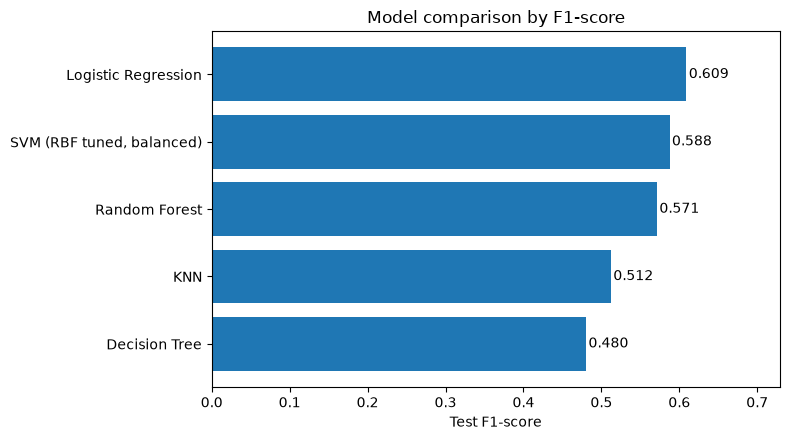

In [18]:
comparison_models = {
    "Decision Tree": (DecisionTreeClassifier(random_state=RANDOM_STATE), X_train, X_test),
    "Random Forest": (RandomForestClassifier(n_estimators=300, random_state=RANDOM_STATE, n_jobs=-1), X_train, X_test),
    "Logistic Regression": (LogisticRegression(max_iter=2000, random_state=RANDOM_STATE), X_train_s, X_test_s),
    "KNN": (KNeighborsClassifier(n_neighbors=5), X_train_s, X_test_s),
}
showdown_rows = []
showdown_models = {}
for name, (model, xtr, xte) in comparison_models.items():
    t0 = time.perf_counter(); model.fit(xtr, y_train); elapsed = time.perf_counter()-t0
    showdown_models[name] = model
    row = evaluate_classifier(name, model, xte, y_test)
    row["Train time (s)"] = elapsed
    showdown_rows.append(row)

svm_options = {
    "SVM (RBF tuned)": (svm_default, time_default),
    "SVM (RBF tuned, balanced)": (svm_balanced, time_balanced),
}
svm_scores = {name: f1_score(y_test, model.predict(X_test_s), zero_division=0) for name,(model,_) in svm_options.items()}
svm_name = max(svm_scores, key=svm_scores.get)
final_model, final_train_time = svm_options[svm_name]
final_X_test = X_test_s
svm_row = evaluate_classifier(svm_name, final_model, X_test_s, y_test)
svm_row["Train time (s)"] = final_train_time
showdown_rows.append(svm_row)

showdown = pd.DataFrame(showdown_rows).set_index("Model")
display(showdown[["Accuracy", "Precision", "Recall", "F1-score", "Train time (s)"]].sort_values("F1-score", ascending=False).round(4))
print("SVM variant included:", svm_name)
print("Best F1 on scoreboard:", showdown["F1-score"].idxmax())
print("Best recall on scoreboard:", showdown["Recall"].idxmax())

f1_order = showdown["F1-score"].sort_values()
fig, ax = plt.subplots(figsize=(8, 4.5))
ax.barh(f1_order.index, f1_order.values)
ax.set_xlabel("Test F1-score"); ax.set_title("Model comparison by F1-score")
for i, v in enumerate(f1_order.values): ax.text(v + 0.003, i, f"{v:.3f}", va="center")
ax.set_xlim(0, min(1, max(f1_order.values)+0.12)); plt.tight_layout(); plt.show()


**Answers**

(a) The printed comparison identifies the model with the highest F1-score and the model with the highest recall. They may be different because F1 balances precision and recall, while recall only measures how many actual churners were found.

(b) Compare the training-time column with the metrics. Extra SVM computation is worthwhile only if its improvement in F1/recall is meaningful for the business; a similar score from a much faster model may be preferable operationally.

(c) I would choose the model based on the business objective, not accuracy alone. I would check at least F1-score and recall, then consider precision and training cost. The table above gives the measured evidence for that decision.

## Part 7 — Final Predictions and Wrap-Up

Export test-set predictions from the selected final SVM. The file includes the true label, predicted label, and probability-like churn score. The notebook also prints an executive summary based on the actual metrics.

In [19]:
final_pred = final_model.predict(final_X_test)
final_scores = final_model.predict_proba(final_X_test)[:, 1]
svm_predictions = pd.DataFrame({
    "true_churn": np.asarray(y_test, dtype=int),
    "predicted_churn": np.asarray(final_pred, dtype=int),
    "predicted_churn_score": np.asarray(final_scores, dtype=float),
}, index=y_test.index)
svm_predictions.index.name = "source_row_index"
svm_predictions.to_csv("svm_predictions.csv", index=True)
print("Saved svm_predictions.csv with", len(svm_predictions), "test predictions.")
display(svm_predictions.head())

final_metrics = evaluate_classifier(svm_name, final_model, final_X_test, y_test)
print("\nEXECUTIVE SUMMARY")
print(f"We evaluated customer churn prediction on {len(df):,} Telco customer records, with churn prevalence of {y.mean():.1%}. ")
print(f"Using a stratified {int((1-TEST_SIZE)*100)}/{int(TEST_SIZE*100)} train/test split, the selected model was {svm_name}. ")
print(f"Its test accuracy was {final_metrics['Accuracy']:.3f}, precision {final_metrics['Precision']:.3f}, recall {final_metrics['Recall']:.3f}, and F1-score {final_metrics['F1-score']:.3f}. ")
print(f"The selected model produced {final_metrics['FN']} false negatives and {final_metrics['FP']} false positives. ")
print("Class weighting was considered because churners are the minority class; the preferred trade-off depends on the business cost of missed churners versus false alarms. ")
print("A limitation is that results depend on this dataset, split, and feature representation; performance may change on newer customer data. ")
print("Preprocessing was fitted on training data only, and the exported CSV contains predictions for the held-out test records.")


Saved svm_predictions.csv with 1409 test predictions.


,true_churn,predicted_churn,predicted_churn_score
source_row_index,,,
437,0,0,0.102568
2280,0,1,0.478445
2235,0,0,0.102101
4460,0,1,0.474660
3761,0,0,0.101731



EXECUTIVE SUMMARY
We evaluated customer churn prediction on 7,043 Telco customer records, with churn prevalence of 26.5%. 
Using a stratified 80/20 train/test split, the selected model was SVM (RBF tuned, balanced). 
Its test accuracy was 0.694, precision 0.458, recall 0.821, and F1-score 0.588. 
The selected model produced 67 false negatives and 364 false positives. 
Class weighting was considered because churners are the minority class; the preferred trade-off depends on the business cost of missed churners versus false alarms. 
A limitation is that results depend on this dataset, split, and feature representation; performance may change on newer customer data. 
Preprocessing was fitted on training data only, and the exported CSV contains predictions for the held-out test records.


### Final Reflection

**(a) Most surprising result:** Use the kernel comparison and model scoreboard above to identify the result that differed most from your expectation. For example, a simpler linear boundary may outperform a more flexible kernel on this dataset.

**(b) What would you try with one more hour?** Possible next steps include threshold tuning using validation data, feature engineering, calibration checks, or a carefully validated resampling strategy such as SMOTE. Any change should be assessed without using the held-out test set for tuning.

---

## Submission checklist
- [ ] Student information is complete (update GitHub and Kaggle profile links if required).
- [ ] All cells have been run from top to bottom without errors.
- [ ] Each plot has a written interpretation.
- [ ] Every question is answered using the run's actual numbers where requested.
- [ ] `svm_predictions.csv` has been downloaded from Colab if required separately.
- [ ] The completed notebook has been pushed to the course GitHub repository.

**Dataset source:** https://www.kaggle.com/datasets/blastchar/telco-customer-churn